# QSO Lorentzian redshift errors: mean P(k) and B(k)

Compare the arithmetic means of the same 25 AbacusHF-lor mocks (0–24), with
`use_dv=False` and `use_dv='verr_lor'`, plus clean and `verr_nonparam`-contaminated `AbacusHF-v2` QSO samples
with the same mock IDs. `mock_mode` selects the AbacusHF-lor variant; the v2
curves use `get_measurement_fn` with the QSO settings from
`plot_clustering`: `domain='cutsky'`, `hod='base_dv'`, `use_dv=False`,
`z_evol=False`, `use_jax=True`, and the default `region='ALL'`; the contaminated
v2 sample changes only `use_dv` to `'verr_nonparam'`. Defaults: combined mocks, GCcomb,
$0.8 < z < 2.1$. Run with the project's **fit_env** Python kernel.

The top panels show mean multipoles with shaded ±1 holi standard-deviation
bands around the clean curves only. Contaminated mocks are shown as lines. The lower panels show
$(\overline{X}_{\rm contaminated}-\overline{X}_{\rm lor,clean})/\sigma_{\rm holi}$
and $(\overline{X}_{\rm contaminated}-\overline{X}_{\rm v2,clean})/\sigma_{\rm holi}$,
where contaminated denotes the AbacusHF-lor `verr_lor` sample. A third solid
residual curve shows `(v2_contaminated − v2_clean) / σ_holi`. All three use
the saved clean QSO holi-v3 `ALL` covariance, matched to the observable.
Here $\sigma_{\rm holi}$ is the scatter of a single realization (no division by
$\sqrt{25}$). Residuals are shown as lines; the gray band marks ±1 holi standard deviation.
Power spectra are rebinned to $\Delta k=0.01$ to match the saved covariance;
bispectra retain $\Delta k=0.005$.
B(k) denotes the stored diagonal Sugiyama bispectrum, $k_1=k_2=k$.
These are the measured spectra, without window deconvolution or model fitting.


In [1]:
import os
import sys
from pathlib import Path

os.environ['MPICH_GPU_SUPPORT_ENABLED'] = '0'
os.environ['JAX_PLATFORMS'] = 'cpu'

import numpy as np
import matplotlib.pyplot as plt
import lsstypes as types

# Locate main/ whether the notebook starts here or at the repository root.
for parent in [Path.cwd(), *Path.cwd().parents]:
    main_dir = parent if (parent / 'cat_tools.py').is_file() else parent / 'main'
    if (main_dir / 'cat_tools.py').is_file():
        break
else:
    raise FileNotFoundError('Run this notebook from within desi_y3_redshift_errors.')
sys.path.insert(0, str(main_dir))
from cat_tools import get_measurement_ready_fn, get_measurement_fn, get_cov_fn

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'text.usetex': False})

In [2]:
region = 'GCcomb'       # 'NGC', 'SGC', or 'GCcomb'
mock_mode = 'combine'   # 'combine' (default) or 'single'
zrange = (0.8, 2.1)
mock_ids = list(range(25))
sample_options = [False, 'verr_lor', 'AbacusHF-v2', 'AbacusHF-v2-contaminated']
labels = {False: 'AbacusHF-lor: clean', 'verr_lor': 'AbacusHF-lor: Lorentzian',
          'AbacusHF-v2': 'AbacusHF-v2: clean',
          'AbacusHF-v2-contaminated': 'AbacusHF-v2: verr_nonparam'}
colors = {False: 'black', 'verr_lor': 'tab:blue', 'AbacusHF-v2': 'tab:orange',
          'AbacusHF-v2-contaminated': 'tab:green'}

catalog = dict(version='AbacusHF-lor', domain='cutsky', tracer='QSO',
               zrange=zrange, region=region, mock_mode=mock_mode)
# Clean QSO settings from plot_clustering; get_measurement_fn defaults to ALL.
data_arges = dict(version='AbacusHF-v2', domain='cutsky', tracer='QSO',
                  zsnap=None, zrange=zrange, use_dv=False, z_evol=False,
                  use_jax=True, hod='base_dv')
catalogs = {False: dict(catalog, use_dv=False),
            'verr_lor': dict(catalog, use_dv='verr_lor'),
            'AbacusHF-v2': data_arges,
            'AbacusHF-v2-contaminated': dict(data_arges, use_dv='verr_nonparam')}
statistics = {
    'pk': dict(kind='mesh2_spectrum_poles', cov_kind='mesh2_spectrum_poles',
               ells=[0, 2], k_range=(0.02, 0.35), kbin=10),
    'bk': dict(kind='mesh3_spectrum_sugiyama-diagonal_poles',
               cov_kind='mesh3_spectrum_poles_sugiyama',
               ells=[(0, 0, 0), (2, 0, 2)], k_range=(0.02, 0.20), kbin=1),
}
# ALL is the available combined-region holi covariance for the GCcomb comparison.
cov_catalog = dict(version='holi-v3', domain='altmtl', tracer='QSO',
                   zrange=zrange, region='ALL', use_dv=False)


In [36]:
# Each array has shape (25 mocks, number of k bins). Missing files raise an
# error, so all four means always contain exactly the same realizations.
spectra = {}
kcoords = {}
covariances = {}
holi_errors = {}
for stat, settings in statistics.items():
    covariance_fn = get_cov_fn(**cov_catalog).format(settings['cov_kind'])
    covariance = types.read(covariance_fn)
    reference = None
    spectra[stat] = {}
    kcoords[stat] = {}
    for sample in sample_options:
        samples = {ell: [] for ell in settings['ells']}
        for mock_id in mock_ids:
            if catalogs[sample]['version'] == 'AbacusHF-v2':
                template = get_measurement_fn(**catalogs[sample], mock_id=mock_id, mkdir=False)
                kind = settings['cov_kind']  # Local mesh3 filename differs from ready-made files.
            else:
                template = get_measurement_ready_fn(**catalogs[sample], mock_id=mock_id)
                kind = settings['kind']
            measurement = types.read(template.format(kind))
            measurement = measurement.select(k=slice(0, None, settings['kbin']))
            measurement = measurement.select(k=settings['k_range']).get(ells=settings['ells'])
            if reference is None:
                reference = measurement
            for ell in settings['ells']:
                pole = measurement.get(ells=ell)
                k = np.asarray(pole.coords('k'))
                if stat == 'bk':
                    np.testing.assert_allclose(k[:, 0], k[:, 1])
                    k = k[:, 0]
                if ell not in kcoords[stat]:
                    kcoords[stat][ell] = k
                # Match bin edges; effective centers can differ between catalogs.
                np.testing.assert_allclose(pole.edges('k'), reference.get(ells=ell).edges('k'),
                                           rtol=1e-6, atol=1e-10)
                samples[ell].append(np.asarray(pole.value()))
        spectra[stat][sample] = {ell: np.stack(values) for ell, values in samples.items()}
        sample_region = catalogs[sample].get("region", "ALL")
        print(f"{stat}: loaded {len(mock_ids)} mocks for {labels[sample]} (region={sample_region})")

    covariance = covariance.at.observable.match(reference)
    covariances[stat] = covariance
    holi_errors[stat] = {}
    for ell in settings['ells']:
        sigma = np.asarray(covariance.at.observable.get(ells=ell).std())
        if sigma.shape != kcoords[stat][ell].shape or not np.isfinite(sigma).all() or np.any(sigma <= 0):
            raise ValueError(f"Invalid matched holi errors for {stat}, ell={ell}.")
        holi_errors[stat][ell] = sigma
    print(f"{stat}: matched clean holi ALL covariance ({covariance.attrs['nobs']} mocks)")

means = {stat: {dv: {ell: values.mean(axis=0) for ell, values in poles.items()}
                for dv, poles in variants.items()} for stat, variants in spectra.items()}

pk: loaded 25 mocks for AbacusHF-lor: clean (region=GCcomb)
pk: loaded 25 mocks for AbacusHF-lor: Lorentzian (region=GCcomb)
pk: loaded 25 mocks for AbacusHF-v2: clean (region=ALL)
pk: loaded 25 mocks for AbacusHF-v2: verr_nonparam (region=ALL)
pk: matched clean holi ALL covariance (846 mocks)
bk: loaded 25 mocks for AbacusHF-lor: clean (region=GCcomb)
bk: loaded 25 mocks for AbacusHF-lor: Lorentzian (region=GCcomb)
bk: loaded 25 mocks for AbacusHF-v2: clean (region=ALL)
bk: loaded 25 mocks for AbacusHF-v2: verr_nonparam (region=ALL)
bk: matched clean holi ALL covariance (846 mocks)


In [37]:
def plot_comparison(stat):
    settings = statistics[stat]
    power = 1 if stat == 'pk' else 2
    symbol = 'P' if stat == 'pk' else 'B'
    fig, axes = plt.subplots(2, len(settings['ells']), figsize=(11, 6),
                             sharex='col', squeeze=False,
                             gridspec_kw={'height_ratios': [2, 1]}, layout='constrained')
    for column, ell in enumerate(settings['ells']):
        ell_label = str(ell) if stat == 'pk' else ''.join(map(str, ell))
        k = kcoords[stat][ell]
        keep = (k >= settings['k_range'][0]) & (k <= settings['k_range'][1])
        k = k[keep]
        weight = k**power
        top, bottom = axes[:, column]
        sigma = holi_errors[stat][ell][keep]
        for sample in sample_options:
            values = spectra[stat][sample][ell][:, keep]
            mean = values.mean(axis=0)
            top.plot(k, weight * mean, color=colors[sample], linestyle='-', label=labels[sample])
            if catalogs[sample]['use_dv'] is False:
                top.fill_between(k, weight * (mean - sigma), weight * (mean + sigma),
                                 color=colors[sample], alpha=0.15)
        bottom.axhspan(-1, 1, color='0.5', alpha=0.10)
        residual_pairs = [
            ('verr_lor', False, 'lor_contaminated − lor_clean', colors[False]),
            ('verr_lor', 'AbacusHF-v2', 'lor_contaminated − v2_clean', colors['AbacusHF-v2']),
            ('AbacusHF-v2-contaminated', 'AbacusHF-v2', 'v2_contaminated − v2_clean',
             colors['AbacusHF-v2-contaminated']),
        ]
        for contaminated, clean, residual_label, color in residual_pairs:
            difference = spectra[stat][contaminated][ell][:, keep] - spectra[stat][clean][ell][:, keep]
            residual = difference.mean(axis=0) / sigma
            bottom.plot(k, residual, color=color, linestyle='-', label=residual_label)
        bottom.axhline(0, color='0.5', linestyle='--', linewidth=1)
        units = r'(h^{-1}\mathrm{Mpc})^2' if stat == 'pk' else r'(h^{-1}\mathrm{Mpc})^4'
        k_label = 'k' if power == 1 else 'k^2'
        top.set_title(rf'${symbol}_{{{ell_label}}}$')
        top.set_ylabel(rf'${k_label}{symbol}_{{{ell_label}}}\;[{units}]$')
        bottom.set_ylabel(rf'$\Delta {symbol}_{{{ell_label}}}/\sigma_{{\rm holi}}$')
        bottom.set_xlabel(r'$k\;[h\,\mathrm{Mpc}^{-1}]$')
        for ax in [top, bottom]:
            ax.grid(alpha=0.2)
    axes[0, 0].legend(fontsize=9)
    axes[1, 0].legend(fontsize=8)
    fig.suptitle(f'QSO | {zrange[0]} < z < {zrange[1]} | {region} | {mock_mode} | mean of {len(mock_ids)} mocks')
    plt.show()
    return fig

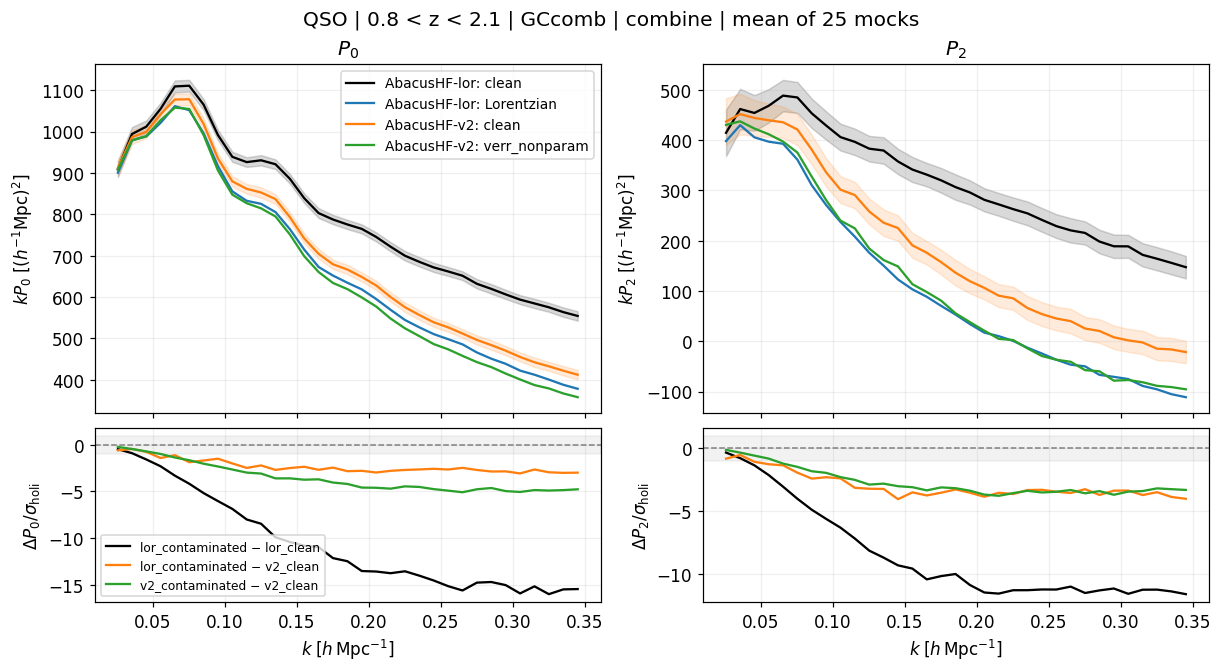

In [38]:
fig_pk = plot_comparison('pk')

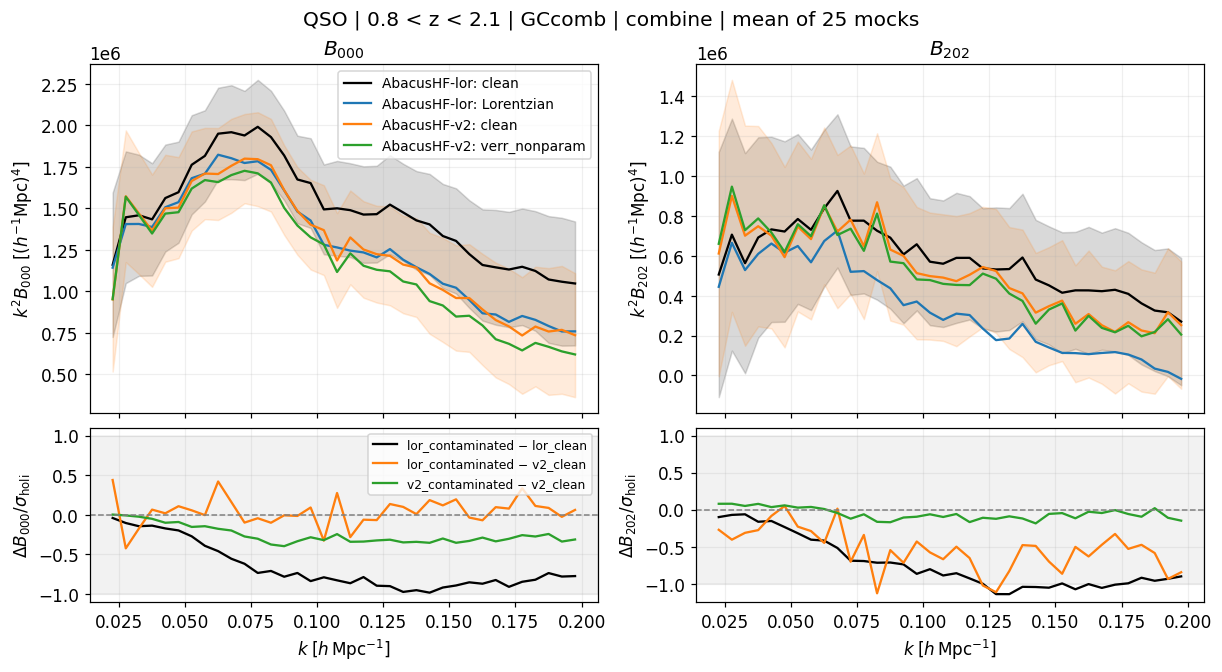

In [39]:
fig_bk = plot_comparison('bk')